# K-Means Clustering

## Importing the libraries

In [53]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings("ignore")

## Importing the dataset

In [54]:
dataset = pd.read_csv('Mall_Customers.csv')

X = dataset.copy()
X["Age_group"] = np.where(X.Age < 18, "0", np.where(X.Age < 25, "1", np.where(X.Age < 30, "2", 
 np.where(X.Age < 35, "3", np.where(X.Age < 40, "4",
 np.where(X.Age < 45, "5", np.where(X.Age < 50, "6", 
 np.where(X.Age < 55, "7", np.where(X.Age < 60, "8", "9")))))))))

X.drop(columns="Age", inplace=True)
X = X.iloc[:, 1:]
X = pd.get_dummies(X, drop_first=True).astype(int)

In [57]:
X

,Annual Income (k$),Spending Score (1-100),Genre_Male,Age_group_2,Age_group_3,Age_group_4,Age_group_5,Age_group_6,Age_group_7,Age_group_8,Age_group_9
0,15,39,1,0,0,0,0,0,0,0,0
1,15,81,1,0,0,0,0,0,0,0,0
2,16,6,0,0,0,0,0,0,0,0,0
3,16,77,0,0,0,0,0,0,0,0,0
4,17,40,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
195,120,79,0,0,0,1,0,0,0,0,0
196,126,28,0,0,0,0,0,1,0,0,0
197,126,74,1,0,1,0,0,0,0,0,0
198,137,18,1,0,1,0,0,0,0,0,0


## Using the elbow method to find the optimal number of clusters

In [58]:
from sklearn.cluster import KMeans

wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init="k-means++", random_state=0)
    km.fit_predict(X)
    wcss.append(km.inertia_)

wcss

[270176.505,
 186105.258239466,
 106533.52621704355,
 73864.0427812005,
 44630.927926555465,
 39041.0359726583,
 32151.320656724227,
 30039.730456558944,
 22389.526298893186,
 20212.52939464681]

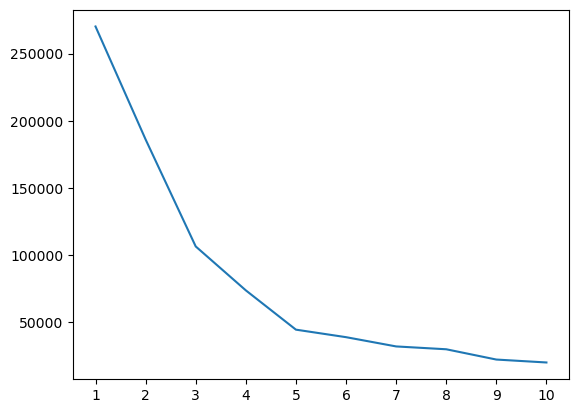

In [59]:
plt.plot(range(1, 11), wcss)
plt.xticks(range(1, 11))
plt.show()

## Training the K-Means model on the dataset

In [60]:
kmeans = KMeans(n_clusters = 5, init = 'k-means++', random_state = 0)
y_kmeans = kmeans.fit_predict(X)

In [62]:
y_kmeans

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 0,
       3, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 1, 2, 1, 2, 1,
       0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 0, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1,
       2, 1], dtype=int32)

## Createing cluster in dataset

In [65]:
dataset["cluster"] = y_kmeans
dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,Male,19,15,39,3
1,2,Male,21,15,81,4
2,3,Female,20,16,6,3
3,4,Female,23,16,77,4
4,5,Female,31,17,40,3
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,2
197,198,Male,32,126,74,1
198,199,Male,32,137,18,2
